In [1]:
import pandas as pd
import numpy as np

# Load the Excel files
consumer_file = '/content/drive/MyDrive/Food additives RAG+LLM/2.10.2 and 2.10.3/explanation quality assessment consumer evaluator.xlsx'
student_file = '/content/drive/MyDrive/Food additives RAG+LLM/2.10.2 and 2.10.3/explanation quality assessment student evaluator.xlsx'

# Read the Excel files, specifying that header is in row 1 (0-indexed)
consumer_df = pd.read_excel(consumer_file, header=1)
student_df = pd.read_excel(student_file, header=1)

# Display the column names to verify
print("Consumer evaluator columns:", consumer_df.columns.tolist())
print("Student evaluator columns:", student_df.columns.tolist())
print()

# Extract the evaluation metrics (excluding Entry # column)
metrics = ['Factual accuracy', 'Clarity', 'Contextual relevance']

# Calculate statistics for Consumer Evaluator
print("=== CONSUMER EVALUATOR RESULTS ===")
consumer_stats = {}
for metric in metrics:
    mean_val = consumer_df[metric].mean()
    std_val = consumer_df[metric].std()
    consumer_stats[metric] = {'mean': mean_val, 'std': std_val}
    print(f"{metric}:")
    print(f"  Mean: {mean_val:.3f}")
    print(f"  Std:  {std_val:.3f}")
    print()

# Calculate statistics for Student Evaluator
print("=== STUDENT EVALUATOR RESULTS ===")
student_stats = {}
for metric in metrics:
    mean_val = student_df[metric].mean()
    std_val = student_df[metric].std()
    student_stats[metric] = {'mean': mean_val, 'std': std_val}
    print(f"{metric}:")
    print(f"  Mean: {mean_val:.3f}")
    print(f"  Std:  {std_val:.3f}")
    print()

# Create a summary table
print("=== SUMMARY TABLE ===")
summary_df = pd.DataFrame({
    'Metric': metrics,
    'Consumer_Mean': [consumer_stats[m]['mean'] for m in metrics],
    'Consumer_Std': [consumer_stats[m]['std'] for m in metrics],
    'Student_Mean': [student_stats[m]['mean'] for m in metrics],
    'Student_Std': [student_stats[m]['std'] for m in metrics]
})

print(summary_df.round(3))

Consumer evaluator columns: ['Entry #', 'Factual accuracy', 'Clarity', 'Contextual relevance']
Student evaluator columns: ['Entry #', 'Factual accuracy', 'Clarity', 'Contextual relevance']

=== CONSUMER EVALUATOR RESULTS ===
Factual accuracy:
  Mean: 3.241
  Std:  1.222

Clarity:
  Mean: 3.444
  Std:  1.079

Contextual relevance:
  Mean: 3.694
  Std:  1.148

=== STUDENT EVALUATOR RESULTS ===
Factual accuracy:
  Mean: 3.759
  Std:  0.682

Clarity:
  Mean: 4.111
  Std:  0.344

Contextual relevance:
  Mean: 4.417
  Std:  0.532

=== SUMMARY TABLE ===
                 Metric  Consumer_Mean  Consumer_Std  Student_Mean  \
0      Factual accuracy          3.241         1.222         3.759   
1               Clarity          3.444         1.079         4.111   
2  Contextual relevance          3.694         1.148         4.417   

   Student_Std  
0        0.682  
1        0.344  
2        0.532  


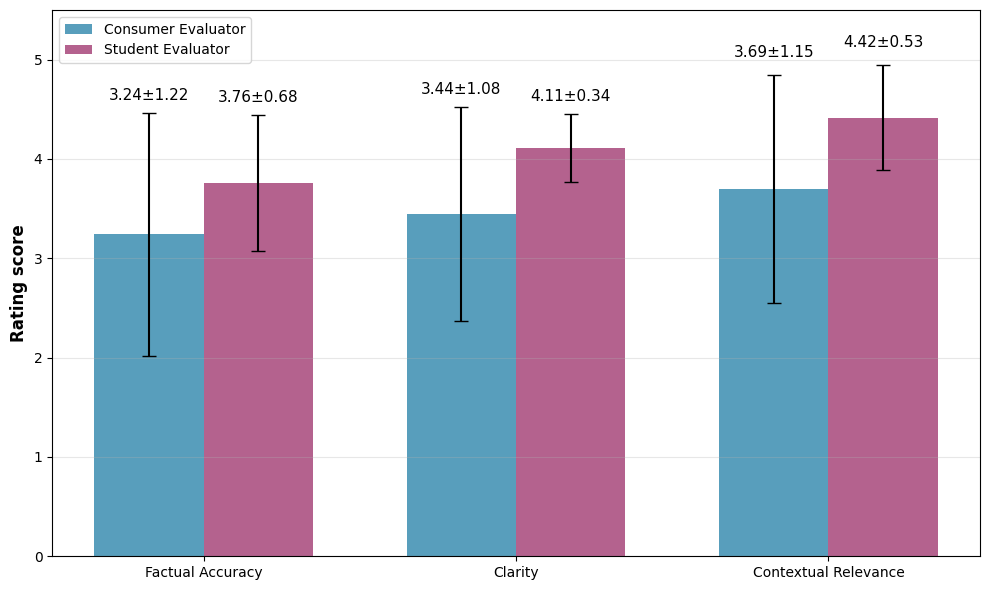

Figure saved as 'explanation_quality_assessment.png'


<Figure size 640x480 with 0 Axes>

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the results
metrics = ['Factual Accuracy', 'Clarity', 'Contextual Relevance']
consumer_means = [3.241, 3.444, 3.694]
consumer_stds = [1.222, 1.079, 1.148]
student_means = [3.759, 4.111, 4.417]
student_stds = [0.682, 0.344, 0.532]

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Set the width of the bars and positions
bar_width = 0.35
x_pos = np.arange(len(metrics))

# Create bars with error bars
bars1 = ax.bar(x_pos - bar_width/2, consumer_means, bar_width,
               yerr=consumer_stds, capsize=5, alpha=0.8,
               label='Consumer Evaluator', color='#2E86AB')

bars2 = ax.bar(x_pos + bar_width/2, student_means, bar_width,
               yerr=student_stds, capsize=5, alpha=0.8,
               label='Student Evaluator', color='#A23B72')

# Customize the plot
ax.set_ylabel('Rating score', fontsize=12, fontweight='bold')
# ax.set_title('Explanation Quality Assessment Results', fontsize=14, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(metrics)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 5.5)  # Extended y-limit to accommodate labels

# Add value labels on top of bars with smart positioning
def add_value_labels(bars, means, stds):
    for i, (bar, mean, std) in enumerate(zip(bars, means, stds)):
        height = bar.get_height()
        # Adjust vertical position based on bar index to avoid overlap
        y_offset = 0.15 if i == 2 else 0.1  # Extra offset for contextual relevance
        ax.text(bar.get_x() + bar.get_width()/2., height + std + y_offset,
                f'{mean:.2f}±{std:.2f}',
                ha='center', va='bottom', fontsize=11)

add_value_labels(bars1, consumer_means, consumer_stds)
add_value_labels(bars2, student_means, student_stds)

# Adjust layout and show
plt.tight_layout()
plt.show()

# Save the figure
plt.savefig('explanation_quality_assessment.png', dpi=600, bbox_inches='tight')
print("Figure saved as 'explanation_quality_assessment.png'")